## Intro : Minimising L2 norm

Linear Regression fits weights $w$ to achieve
$${X}w=\hat{y}$$
(Note that a column of 1s is appended to ${X}$ so as to allow an intercept. Each row of $X$ is a data point; this is standard practice in most _code_ I have encountered, so I will stick to this. Note that typically in theoretical discussions people instead define $X$ so that each column is a data point, so if you are looking at any other sources, this file may swap their $X^T$ for my $X$.)

$$ {X} \in \mathbb{R}^{n \times d}, \quad
y \in \mathbb{R}^{n}, \quad
w \in \mathbb{R}^{d} $$
We use the squared L2 norm as the loss:

\begin{eqnarray*}
J &=& \|y-{X}w\|_2^2 \\
 &=& (y-{X}w)^T(y-{X}w) \\
 &=& y^Ty - y^T{X}w -w^T{X}^Ty + w^T{X}^T{X}w \\
 &=& y^Ty - 2w^T{X}^Ty + w^T{X}^T{X}w
\end{eqnarray*}

Where the middle two terms were merged since just like $J$, all 4 are scalar terms, and they all equal their own transpose.

Giving the following gradient (whose computation in the absence of prior knowledge of gradient formulae involves a bit of pen and paper shennanigans)

$$\nabla J = - 2{X}^Ty + 2{X}^T{X}w $$

For optimality, the gradient is zero, giving
$$2{X}^T{X}w^*  = 2{X}^Ty $$
$$\implies \boxed{w^* = ({X}^T{X})^{\dagger} {X}^Ty}$$

where $^{\dagger}$ denotes the pseudoinverse.

## Projections

We have

$$Xw=\hat{y}$$

Using free reign over vector $w$, we can get any linear combination of the feature vectors in matrix $X$. The vector $y$ is also in the same $n$ dimensional space, and we desire for a $\hat{y}$ residing in the column space of $X$, *closest* to $y$.

<div align="center">
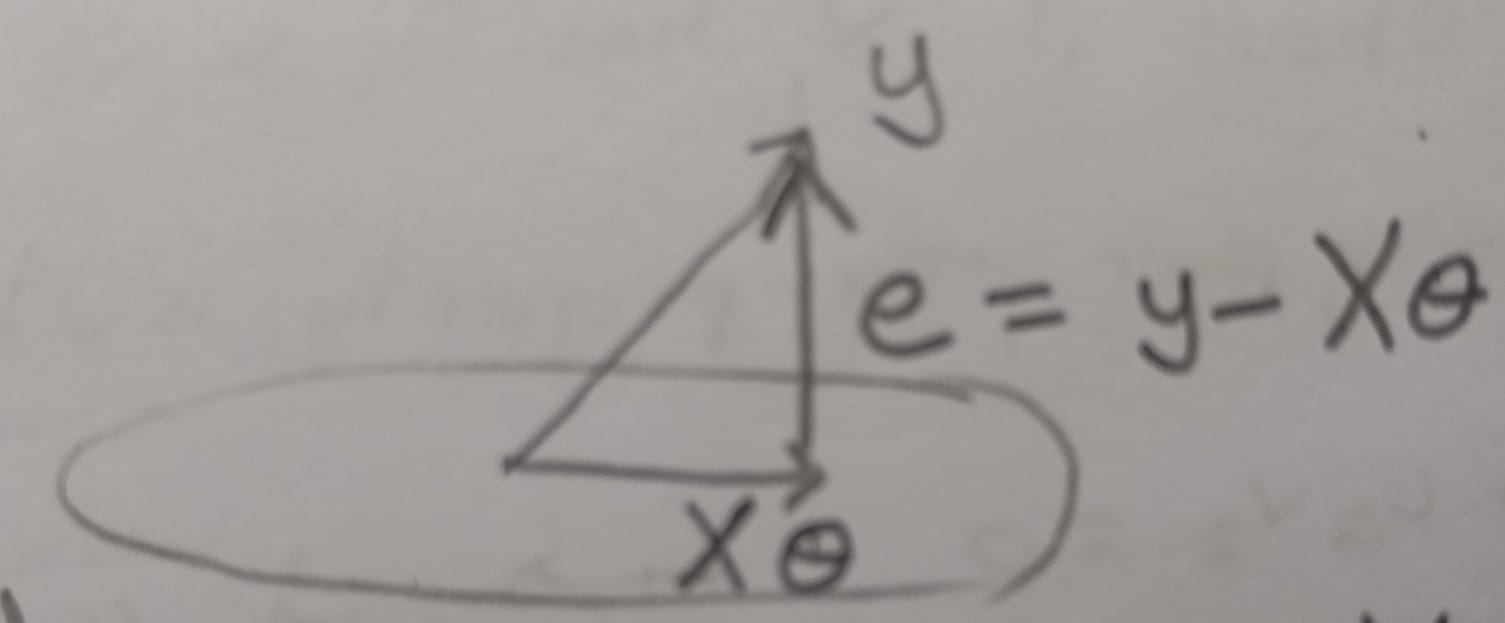
</div>

Observe that $e$ is orthogonal to the subspace spanned by $X$.

If $e$ were not orthogonal to $Xw$ ($X\theta$ in the image) then there exists a component of $e$ in the subspace spanned by $X$. Then, there exists another vector $Xw'$ with that component added to it, which results in a smaller $e$.

Thus, the closest point in the subspace to $y$, must be orthogonal to every column of the matrix $X$:

$$X^T(y-Xw) = 0 $$
$$ X^Ty = X^TXw$$
$$\implies \boxed{w^* = ({X}^T{X})^{\dagger} {X}^Ty}$$

Here, we solved for $w^*$ much more elegantly using geometry, whereas the traditional method simply used the actual distance function and minimised it to get the closest point within the subspace. Either way, we derived that the projection matrix $\mathbb{P} = X({X}^T{X})^{\dagger} {X^T}$. ($w$ is not the projection, $Xw$ is.)

(For 1D, this simply becomes $x \cdot \frac{1}{x^Tx} \cdot x^T$ which is cute.)


## Gradient Descent

Solving the equation explicitly for $w^*$ may be too computationally intensive for large $X$, so gradient descent is preferred. (If $d$ is too large, inverse step of $O(d^3)$, is too costly; if $n$ is in the hundreds of millions, even finding $X^TX$ will be too expensive.) Here, the loss is a strictly convex function, so gradient descent will find the global minimum without much of an issue.

To run gradient descent on some dataset with a large $n$, we compute the gradient on a small batch of data $\tilde{X}$
$$\nabla J = - 2\tilde{X}^T\tilde{y} + 2\tilde{X}^T\tilde{X}w $$

and use this to take a small step. Unlike normal gradient descent, where we are assured to step in the right direction, here we may get unlucky with our gacha pull on the sample and step any which way. Thus, instead of outputting the final $w$, we use the average of the last $k$ results, for some choice of $k$.

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

X, y = fetch_california_housing(as_frame=True, return_X_y=True)

X_train_full, X_test, y_train_full, y_test  = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_dev, y_train, y_dev = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

In [ ]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

sgd = SGDRegressor(random_state=42, tol=None)
sgd.fit(X_train,y_train)

train_mse = mean_squared_error(y_train, sgd.predict(X_train))
dev_mse = mean_squared_error(y_dev, sgd.predict(X_dev))
print(f"MSE on Train set: {train_mse} \nMSE on dev set: {dev_mse}")
print(f"Num epochs trained: {sgd.n_iter_}")

MSE on Train set: 8.211430514541365e+28 
MSE on dev set: 8.076850578843385e+28
Num epochs trained: 1000


$10^{28}$?!

After 1000 epochs?

SGD is terrible if the features aren't normalised.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

sgd_pipe = Pipeline([("feature_scaling", StandardScaler()),
                         ("sgd", SGDRegressor(random_state=42,
                                              tol=None))])
sgd_pipe.fit(X_train, y_train)

train_mse = mean_squared_error(y_train, sgd_pipe.predict(X_train))
dev_mse = mean_squared_error(y_dev, sgd_pipe.predict(X_dev))
print(f"MSE on Train set: {train_mse} \nMSE on dev set: {dev_mse}")
print(f"Num epochs trained: {sgd_pipe[-1].n_iter_}")

MSE on Train set: 0.5158524743184035 
MSE on dev set: 0.5307410104333737
Num epochs trained: 1000


Well, that's much better.

I had to turn off the tolerance param in both the above cells to force it to run 1000 iterations, otherwise, for some reason, it just plateaus in loss very rapidly and gives up training in less than 10 epochs.

SGD as with anything in ML comes with its own hyperparameters which can sometimes sneakily land a critical hit on you. Tuning these is what the dev dataset is for. We can observe the training loss epoch by epoch to make a good judement on setting the learning rate:

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def show_learning_curves(learning_rates):
  for lr in learning_rates:

      sgd_pipe = Pipeline([
          ("feature_scaling", StandardScaler()),
          ("SGD", SGDRegressor(
              max_iter=1,
              tol=None,
              warm_start=True,
              #learning_rate="constant",
              eta0=lr,
              random_state=42
          ))
      ])

      losses = []

      for epoch in range(100):
          sgd_pipe.fit(X_train, y_train)
          y_pred = sgd_pipe.predict(X_dev)
          losses.append(mean_squared_error(y_dev, y_pred))

      plt.plot(losses, label=f"eta0={lr:.0e}")

  plt.xlabel("Epoch")
  plt.ylabel("MSE")
  plt.legend()
  plt.show()

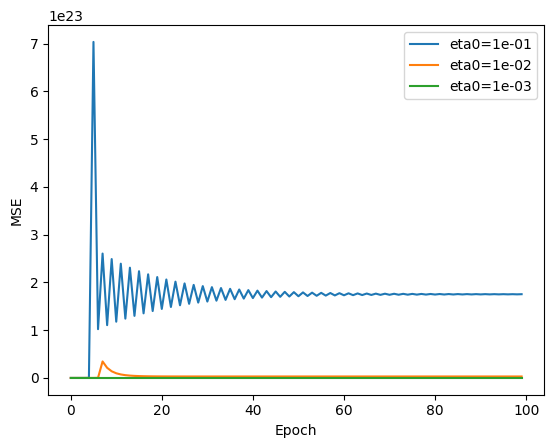

In [ ]:
show_learning_curves([1e-1,1e-2,1e-3])

Note that the learning rate actually decays by default in SGDRegressor and that is redeeming the high values of 0.1 and 0.01 in this case. If we set the lr to be constant, (which you can uncomment back in to see for yourself) all the three lines stabilse incredibly fast at a bad loss. The 1e-2 and 1e-1 are messing up the scale of the y axis, and setting it to 1e23. 1e-2 which was the default was actually a terrible rate but it lucky found the optimum.

With this knowledge, we can try better values:

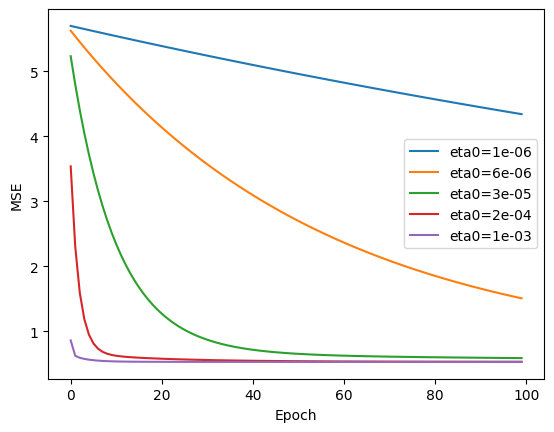

In [ ]:
show_learning_curves(np.logspace(-6, -3, 5))

Looks like 1e-3 was the best choice.

In this case, we won't see much an up in the final performance with the LR change, because 1e-2 also hit the optimum and the inverse decay of the setup helped it out. In general though, using a gridsearch and tuning hyperparams is the way to go, and I will be doing this a lot later.


## Probabalistic Model

Consider the following probabalistic model:

This is the natural process of how true labels $y$ are generated from the data $X$: There exists a fixed true $w$ which we wish to discover, that satisfies:  $$y = Xw + \epsilon$$
where $\epsilon$ is a corrupting noise. Put another way, $p(y_i \mid x_i, w) = \mathcal{N}(x_i^T w,\sigma^2).$

- We assume that $$\epsilon \sim N(0,\sigma^2)$$

Now, given the data $X$ and labels $y$, we know the likelihood of $w$ being a particular value (if unfamiliar with likelihood, see *ML vs MAP Estimators* <a href="#scrollTo=foUGK8GVsKeF">below</a>):
$$\mathcal{L}(w \mid X,y)= \prod_{i=1}^n \frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(-\frac{(y_i - x_i^T w)^2}{2\sigma^2}\right)$$

$$\log \mathcal{L}(w \mid X,y)
= -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^n (y_i - x_i^T w)^2$$

We now seek to find the $w$ that maximises the Likelihood function, $\hat{w}_{ML}$. The first term is constant with respect to $w$, so maximizing the log-likelihood is equivalent to minimizing:
$$\sum_{i=1}^n (y_i - x_i^T w)^2 = \|y - Xw\|_2^2 $$

This is exactly the SSE loss function we minimsed earlier.

### Other Losses

Although the use of SSE as the loss was rather arbitrary earlier, it is now backed by a solid reasoning: the $w$ we obtain by optimising SSE is $\hat{w}_{ML}$ assuming a gaussian error corrupts the generating process.

If we assumed the error was Laplacian,
$$p(\epsilon)=\frac{1}{2b}\exp\left(-\frac{|\epsilon|}{b}\right)$$

$$
\mathcal{L}(w \mid X,y)
= \prod_{i=1}^n \frac{1}{2b}
\exp\left(-\frac{|y_i - x_i^T w|}{b}\right).
$$

Taking the log-likelihood:
$$
\log \mathcal{L}(w \mid X,y)
= -n\log(2b) - \frac{1}{b}\sum_{i=1}^n |y_i - x_i^T w|.
$$

Ignoring constants, we need to minimise:
$$
\sum_{i=1}^n |y_i - x_i^T w|.
$$

Which is the L1 norm.

The implication of the probabilistic understanding of regression is that every loss function corresponds to an error model in the generating process, and that the L2 norm is a well motivated commonly applicable error.

### ML vs MAP Estimators:

If we have a prior estimate on what the paramter $\theta$ could be, we seek the Maximum Apositerori estimate once we observe some data:

$$ \hat{\theta}_{MAP} = \arg\max_{\theta} f(\theta \mid x)$$

Using Bayes’ theorem:

$$f(\theta \mid x) = \frac{f(x \mid \theta) \cdot f(\theta)}{f(x)} $$

Since $f(x)$ is merely a constant normalising factor not relevant to $\theta$, and can be ignored:

$$ \hat{\theta}_{MAP} = \arg\max_{\theta} f(x \mid \theta) \cdot f(\theta)$$

If we have no prior idea, i.e the prior is uniform, then it too is a constant that can be ignored:

\begin{eqnarray}
\hat{\theta}_{MAP} &=& \arg\max_{\theta} f(x \mid \theta)\\  
&=& \arg\max_{\theta} \mathcal{L}(\theta \mid x) \\
&=& \hat{\theta}_{ML}
\end{eqnarray}


## Regularization: A better estimator

### Evaluating Estimators

Although it's incredibly natural to pick the Maximum likelihood estimator, this is not necessarily the best one. The goodness of an estimator is measured with its MSE:

$$\mathbb{E}[\|\hat\theta - \theta\|^2]$$

Why? It's convenient. As a result, of course, it's been studied to death. MSE decomposes as :

$$MSE = Var + Bias^2$$

Here's a quick proof, first for one dimension:
$$(\hat{\theta} - \mathbb{E}[\hat{\theta}] + \mathbb{E}[\hat{\theta}] - \theta)^2$$

$$ = (\hat{\theta} - \mathbb{E}[\hat{\theta}])^2 + 2(\hat{\theta} - \mathbb{E}[\hat{\theta}])(\mathbb{E}[\hat{\theta}] - \theta)+  (\mathbb{E}[\hat{\theta}] - \theta)^2
$$

In expectation, the cross terms vanish, as $$\mathbb{E}[\hat{\theta} - \mathbb{E}[\hat{\theta}]] = 0$$

\begin{eqnarray}
\implies \mathbb{E}[(\hat\theta - \theta)^2] &=& (\hat{\theta} - \mathbb{E}[\hat{\theta}])^2 + (\mathbb{E}[\hat{\theta}] - \theta)^2\\
&=& Var(\hat{\theta}) + Bias(\hat{\theta})^2
\end{eqnarray}

For the multidimensional case, the squared L2 norm is merely

$$\sum_{i=1}^n(\hat\theta_i - \theta_i)^2$$

The variances of all parameters is found in the diagonal entries of the covariance matrix $CoV(\hat\theta)$. Since the above summation results in the addition of the variances of each $\hat\theta_i$, it adds to $Tr(CoV(\hat\theta))$. The addition of squared biases of $\hat\theta_i$, is concisely the squared L2 norm of the bias vector of $\hat\theta$. Thus,

$$\mathbb{E}[\|\hat\theta - \theta\|^2] = Tr(CoV(\hat\theta)) + Bias(\hat\theta)^2$$

A good estimator tends to minimise both bias and variance, but in practice, we often end up sacrificing one for the other. The Var of any estimator is lower bounded by the Cramer Rao bound (CRLB). A discussion on CRLB, its proof and Fischer information is too tangential and I'm opting to skip it.


### Performance of $\hat{w}_{ML}$



$$
\hat{w}_{ML} = (X^T X)^{-1}X^T y.
$$

Substituting $y = Xw + \epsilon$,
$$
\hat{w}_{ML} = w + (X^T X)^{-1}X^T \epsilon.
$$

Which clearly is unbiased. Now,

\begin{eqnarray}
\mathrm{CoV}(\hat w_{ML}) &=& \mathbb{E}\big[(\hat w_{ML} - w)(\hat w_{ML} - w)^T\big] \\
&=& \mathbb{E}\left[(X^T X)^{-1} X^T \epsilon \epsilon^T X (X^T X)^{-1}
\right]\\
 &=& (X^T X)^{-1} X^T \mathbb{E}[\epsilon \epsilon^T]X (X^T X)^{-1} \\
&=& \sigma^2 (X^T X)^{-1} X^T X (X^T X)^{-1} \\
&=& \sigma^2 (X^T X)^{-1}
\end{eqnarray}

This is actually the Inverse Fisher Information (meets the CRLB) and this proves that we have found the best unbiased estimator possible in $\hat{w}_{ML}$. A more general proof that does not assume a normal error is given by the Gauss-Markov theorem (opting to not discuss here). Evaluating the MSE for our estimator, we have:

\begin{eqnarray}
\|\hat{w}_{ML} - w \|^2 &=& Tr(CoV) + Bias^2 \\
&=& \sigma^2 Tr[(X^T X)^{-1}]
\end{eqnarray}

Although we have been handed from high up that this is somehow the best variance, we can tweak the estimator by looking at it closely. For any matrix, the trace is equal to the sum of its eigenvalues: $Tr(A) = \sum_i^n \lambda_i$ (This can be easily proved using the SVD and rotating the matrices within the trace)

The cost function has boiled down essentially, to the sum of the eigenvalues of the inverse of the covariance matrix of the data. (lmao) (data = $X^T$, unfotunate result of my notation) Since $A^{-1}$ has eigenvalues that are inverse to those of $A$ ($\frac{1}{\lambda}$), We are looking at

$$\frac{1}{\lambda_1} + \frac{1}{\lambda_2} \dots \frac{1}{\lambda_n}$$

The way this cost can blow up is if CoV of the data has small eigenvalues. This occurs if the data is of low dimensionality and has linearly dependent features. (again, think of the SVD/PCA) One way to circumvent this is by adding a constant to all the eigenvalues and preventing a high cost, that is, making this into $Tr[(X^TX + \alpha I)^{-1}]$. If we just plug that into the estimator, we can make a _really unprincipled guess_:

$$\hat{w} = (X^T X + \alpha I)^{-1}X^T y$$

This is particularly unprincipled not only because this is no longer even the correct variance term, we introduce a bias term, which might drive up the cost more than it saves by softening the blow from small eigenvalues. Turns out actually though, that it is _provable_ that there exists _some_ $\alpha$ for whcich this estimator has a lower MSE than the ML estimator.

### MAP Estimation


Recall

$$ \hat{\theta}_{MAP} = \arg\max_{\theta} f(x \mid \theta) \cdot f(\theta)$$

Substituting the likelihood we get:

\begin{eqnarray}
f(w \mid X,y)&\propto& \prod_{i=1}^n \frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(-\frac{(y_i - x_i^T w)^2}{2\sigma^2}\right) \cdot f(w)\\
&\propto&
\exp\left(-\frac{\sum_i^n(y_i - x_i^T w)^2}{2\sigma^2}\right) \cdot f(w)\\
&\propto&  \exp\left( -\frac{1}{2\sigma^2} \cdot \|y-Xw\|^2 \right) \cdot f(w)
\end{eqnarray}

We seek a conjugate prior such that $f(w)$ fuses with the likelihood to return a posterior of the same distribution. This is naturally a gaussian.

Taking $f(w) ~  \sim N(0,\gamma^2)$ We have a new cost function to minimise:

$$J = \frac{1}{2\sigma^2} \cdot \|y-Xw\|^2 + \frac{1}{2\gamma^2} \cdot \|w\|^2 $$

we take the gradient of J to get $\hat{w}_{MAP}$:

$$ -\frac{1}{\sigma^2}({X}^Ty - {X}^T{X}\hat{w}_{MAP})  + \frac{\hat{w}_{MAP}}{\gamma^2}  = 0$$
$$\implies {X}^Ty = (X^TX + \frac{\sigma^2}{\gamma^2}I)\hat{w}_{MAP}$$

$$\hat{w}_{MAP} = (X^TX + \frac{\sigma^2}{\gamma^2}I)^{-1}{X}^Ty$$

which is the ridge estimator. We shall henceforth call the ridge parameter $\frac{\sigma^2}{\gamma^2} = \alpha$ as $\lambda$.

### Geometry

The ridge estimator constrains the length of the $w$ vector. It can be shown that the problem of ridge regression is equivalent to solving the least squares problem but with a constraint that the length of the $w$ cannot exceed a certain value.

When I imagine the loss in 3D, with 2 parameters (x and y) for w, the quadratic loss is a paraboloid, and its contours will be ellipsoids. Ridge is the interesection of the ellipsoids projected to the 2D plane with a circle around the origin.

Using an L1 constraint is known as LASSO regression, and it seeks to set as many features as possible to exactly zero by constraining the weight vector to a sharp diamond shaped box with corners on the axes, which is likely to intersect the concentric ellipsoids at the corners.

## Cross Validation

Although it is assured that there exists _some_ constant $\lambda$ for which the ridge regression is better than the OLS (ordinary least squares) estimator, we have no way to obtain knowledge about the true value of $lambda$ in practice.

In practice, we opt to make a good guess using trial and error. Essentially, we train with several values of lambda and see how it generalises, and pick the best lambda.

If we simply split the data into train and test, and use test loss to get best lambda, we firstly bias the model to fit the test, and secondly, we may not find the real best lambda due to a random bias in the selection of the test set. Thus, we instead split the train data into n folds, hold off on one fold as "validation", train on the rest and evaluate on val. We do this by holding off on each fold, to get n evaluations, and the mean score here is used as the performance indicator for lambda.

Sometimes models are too intensive to do n fold cross validation, so a simple train, val, test split is made, and the hyperparameters are tuned with val score after training on train data. Note that even though we don't train explicitly on val, because we use it as a metric to optimise, it is not totally foreign data when considering an evaluation, which is why a 3 way split is necessary.

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import train_test_split

from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge

X, y = fetch_california_housing(as_frame=True, return_X_y=True)
X_train, X_test, y_train, y_test  = train_test_split(X, y, random_state=42)

cv = ShuffleSplit(n_splits=10, test_size=0.2, random_state=42)

In [ ]:
lin_reg_pipeline = Pipeline([("feature_scaling", StandardScaler()),
                             ("lin_reg", LinearRegression())])

poly_reg_pipeline = Pipeline([("poly", PolynomialFeatures(degree=2)),
                              ("feature_scaling", StandardScaler()),
                              ("lin_reg", LinearRegression())])

ridge_reg_pipeline = Pipeline([("poly", PolynomialFeatures(degree=2)),
                              ("feature_scaling", StandardScaler()),
                              ("ridge", Ridge(alpha=0.5))])

In [ ]:
pipes = [lin_reg_pipeline, poly_reg_pipeline, ridge_reg_pipeline]
for pipe in pipes:
  cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
  print(f"Mean train error: {-1*cv_results['train_score'].mean():.3f} +/- {cv_results['train_score'].std():.3f}")
  print(f"Mean test error: {-1*cv_results['test_score'].mean():.3f} +/- {cv_results['test_score'].std():.3f} \n")


Mean train error: 0.522 +/- 0.004
Mean test error: 0.517 +/- 0.015 

Mean train error: 0.420 +/- 0.006
Mean test error: 4.029 +/- 5.517 

Mean train error: 0.439 +/- 0.006
Mean test error: 0.697 +/- 0.286 



Clearly, polynomial features are overfitting, and ridge is able to control and lower the loss. We now need to tune for the ridge paramter alpha. The CV split used above was just to get a better estimate of the test score, nothing was tuned.

In [ ]:
import numpy as np
from sklearn.linear_model import RidgeCV

alpha_list = np.logspace(-4, 4, num=20)
ridge_reg_pipeline = Pipeline([("poly", PolynomialFeatures(degree=2)),
                              ("feature_scaling", StandardScaler()),
                              ("ridge_cv", RidgeCV(alphas=alpha_list,
                                                   cv=cv,
                                                   scoring="neg_mean_squared_error"))])

ridge_reg_cv_results = ridge_reg_pipeline.fit(X_train, y_train)

print ("The error with the best alpha is:", f"{-ridge_reg_cv_results[-1].best_score_:.3f}")
print ("The best value for alpha:", ridge_reg_cv_results[-1].alpha_)

The error with the best alpha is: 0.530
The best value for alpha: 545.5594781168514


Note that when fit is called on the Ridge Estimator, it fits to the data with ridge loss and the RidgeCV estimator fits for each alpha and each CV split, finding the alpha with the lowest mean CV loss and presenting the final model.

In general though, the GridSearchCV utility is broadly applicable:

In [ ]:
from sklearn.model_selection import GridSearchCV

ridge_pipeline = Pipeline([("poly", PolynomialFeatures(degree=2)),
                              ("feature_scaling", StandardScaler()),
                              ("ridge", Ridge())])

param_grid = {'poly__degree': (1, 2, 3),
              'ridge__alpha': np.logspace(-4, 4, num=20)}


ridge_grid_search = GridSearchCV(ridge_pipeline,
                                 param_grid=param_grid,
                                 n_jobs=2,
                                 cv=cv,
                                 scoring="neg_mean_squared_error",
                                 return_train_score=True)

ridge_grid_search.fit(X_train, y_train)

print ("The best parameters are:", ridge_grid_search.best_params_)
print ("Mean cross validated test error of the best estimator is: ", -ridge_grid_search.best_score_)

The best parameters are: {'poly__degree': 1, 'ridge__alpha': np.float64(4.281332398719396)}
Mean cross validated test error of the best estimator is:  0.5171012607481125


Param grid must compulsarily use the key "pipeline step name __ parameter name" (Eg: poly__degree) for gridsearchcv to plug the paramter into the pipeline properly. Each dunder in the name is a sign for it to find a member, so this can work even in nested pipelines; the name could be "pipe_2__poly__degree" and the correct param would be picked out.

In [ ]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([("poly", PolynomialFeatures(degree=2)),
                              ("feature_scaling", StandardScaler()),
                              ("lasso", Lasso())])

param_grid = {'poly__degree': (1, 2, 3),
              'lasso__alpha': np.logspace(-4, 4, num=20)}


lasso_grid_search = GridSearchCV(lasso_pipeline,
                                 param_grid=param_grid,
                                 n_jobs=2,
                                 cv=cv,
                                 scoring="neg_mean_squared_error",
                                 return_train_score=True)

lasso_grid_search.fit(X_train, y_train)

print ("The best parameters are:", lasso_grid_search.best_params_)
print ("Mean cross validated test error of the best estimator is: ", -lasso_grid_search.best_score_)

The best parameters are: {'lasso__alpha': np.float64(0.012742749857031334), 'poly__degree': 3}
Mean cross validated test error of the best estimator is:  0.5161662735199509


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.667e+01, tolerance: 2.066e+00
  model = cd_fast.enet_coordinate_descent(
